# DATFuse (dual attention transformer, infrared + visible fusion)

Fusion method for the `fusion/` pipeline. Save this notebook as `fusion/methods/transformers/datfuse.ipynb`.

- **Input:** `fusion/data/<SOURCE>/` with `rgb/` + `ir/` image sequences (same filenames, frame-aligned), or `visible.mp4` + `thermal.mp4`.
  `SOURCES` lists the clips to fuse; the default is the three Blender forest test clips.
- **Output:** `fusion/out/datfuse_<SOURCE>.mp4` (grayscale fused video, same resolution and frame count as the input).

- **Method:** DATFuse (Tang et al., IEEE TCSVT 2023) from [tthinking/DATFuse](https://github.com/tthinking/DATFuse),
  with the released weights (`model_10.pth`, in the repo). Cloned on first run into `fusion/methods/_vendor/DATFuse/`.
  Needs `timm`. Fully convolutional apart from its "Swin" block, whose window size is 1: each attention sees a single
  token, so the transformer part acts as a per-token MLP. Any input size works.
- **Checked:** on the repo's own sample pair this notebook's model call reproduces the repo's `fusion results/2.bmp`
  exactly. The output is the network's tanh output used as-is (the repo writes `out * 255`); we clip to 0..1 because
  the repo's uint8 cast would wrap negative values.
- **Speed:** `FRAME_STEP = 1` (default) fuses every frame, as rfn_nest does; use a GPU. On CPU, `FRAME_STEP = 10` fuses
  only the frames `FUSION_EVALUATION.ipynb` scores (every 10th) and repeats each one until the next: same scores,
  a tenth of the time, but the video updates only 3 times per second.

Locally: set `SOURCES`, select the `.venv` kernel, run all cells. On **Colab** (T4 GPU): `forest_batch_1.zip` must be on Drive at `DRIVE_DATA`, as for `rfn_nest_blender`; the clips are unzipped into `/content` and the videos are written to `DRIVE_OUT/out`. Then score the result with `fusion/FUSION_EVALUATION.ipynb`.

In [1]:
METHOD = 'datfuse'            # output file: fusion/out/<METHOD>_<SOURCE>.mp4

SOURCES = ['forest_01_night-moon_nadir-hover',   # folder names inside fusion/data/ (default: the three Blender
           'forest_07_afternoon_steep-push',     # forest test clips, the same ones the rfn_nest_blender notebooks
           'forest_10_dusk_high-orbit']          # hold out)

# Colab only (same Drive layout as rfn_nest_blender_v*.ipynb); locally fusion/data and fusion/out are used
DATASET = 'forest_batch_1'
DRIVE_DATA = '/content/drive/MyDrive/Vidhance Extended View/Blender renders/forest_batch_1.zip'   # .zip, or the forest_batch_1 folder
DRIVE_OUT = '/content/drive/MyDrive/Vidhance Extended View/models_output/transformers'           # videos go to DRIVE_OUT/out

SCALE = 1                     # fuse at this fraction of the input size (output is resized back to full size)
MAX_FRAMES = None             # None = all frames, or an int to fuse only the first N
FRAME_STEP = 1                # fuse every n-th frame and repeat it until the next one (keeps the frame count).
                              # 10 = exactly the frames FUSION_EVALUATION scores (EVAL_STRIDE = 10), so the scores equal
                              # a full run at a tenth of the cost; 1 = fuse every frame (a smooth video to watch)
FPS = 30.0                    # frame rate for image-sequence inputs (videos keep their own)
OVERWRITE = True              # False = skip clips whose output already exists
PREVIEW_FRAME = 100           # frame index shown in the preview at the end (a multiple of FRAME_STEP)

DAT_CKPT = None               # None -> the repo's released weights (model_10.pth)

In [2]:
import os, sys, shutil, subprocess, time, zipfile, importlib
from itertools import islice
from pathlib import Path

def _need(mod, pip_name=None):                       # fallback if requirements.txt was not installed
    try:
        importlib.import_module(mod)
    except ImportError:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', pip_name or mod], check=True)

for _m, _p in [('numpy', None), ('cv2', 'opencv-python'), ('torch', None), ('timm', None), ('tqdm', None), ('matplotlib', None)]:
    _need(_m, _p)

import numpy as np, cv2, torch
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:                                         # same layout as rfn_nest_blender_v*.ipynb
    drive.mount('/content/drive')
    if not torch.cuda.is_available():
        raise RuntimeError('No GPU: choose Runtime > Change runtime type > T4 GPU, then run all cells again.')
    VENDOR = Path('/content/_vendor')
    BATCH_ROOT = Path('/content/data') / DATASET     # forest_batch_1 unzipped from Drive
    DATA_DIR = Path('/content/fusion_data')          # forest_<clip>/{rgb,ir,clear} built from it below
    OUT_DIR = Path(DRIVE_OUT) / 'out'
else:
    here = Path.cwd().resolve()
    fusion = next((d / 'fusion' for d in [here, *here.parents] if (d / 'fusion' / 'data').is_dir()),
                  next((d for d in [here, *here.parents] if d.name == 'fusion' and (d / 'data').is_dir()), None))
    if fusion is None:
        raise FileNotFoundError('Could not find fusion/data from %s. Start Jupyter inside the repo.' % here)
    VENDOR = fusion / 'methods' / '_vendor'          # third-party code is cloned here (add to .gitignore)
    DATA_DIR, OUT_DIR = fusion / 'data', fusion / 'out'

STREAMS = ('visible_haze', 'visible_clear', 'thermal_haze')
VIS_W, VIS_H, TH_Y0, TH_Y1 = 1280, 720, 76, 436      # thermal -> visible registration, as in rfn_nest_blender

def prepare_colab_sources():
    """Unzips forest_batch_1 from Drive (first run only) and writes forest_<clip>/{rgb,ir,clear} for SOURCES,
    the same files rfn_nest_blender exports: rgb = visible_haze, clear = visible_clear, ir = registered thermal_haze."""
    clips = [s[len('forest_'):] for s in SOURCES if s.startswith('forest_')]
    complete = lambda: all((BATCH_ROOT / c / 'frames' / s).is_dir() for c in clips for s in STREAMS)
    if BATCH_ROOT.is_dir() and not complete():
        print('The copy in %s is incomplete (interrupted unzip?), replacing it.' % BATCH_ROOT)
        shutil.rmtree(BATCH_ROOT)
    if not BATCH_ROOT.is_dir():
        src, t0 = Path(DRIVE_DATA), time.time()
        if not src.exists():
            raise FileNotFoundError('%s not found. Upload %s to Drive or change DRIVE_DATA.' % (src, DATASET))
        BATCH_ROOT.parent.mkdir(parents=True, exist_ok=True)
        if src.is_dir():
            print('copying the folder from Drive, this can take a long time for this many files...')
            shutil.copytree(src, BATCH_ROOT)
        else:
            with zipfile.ZipFile(src) as zf:
                zf.extractall(BATCH_ROOT.parent)
        print('data ready in %.0f s' % (time.time() - t0))
    for clip in clips:
        frames, dst = BATCH_ROOT / clip / 'frames', DATA_DIR / ('forest_' + clip)
        names = sorted(p.name for p in (frames / 'visible_haze').iterdir() if p.suffix == '.png')
        if (dst / 'ir').is_dir() and len(list((dst / 'ir').iterdir())) == len(names):
            continue
        dst.mkdir(parents=True, exist_ok=True)
        for sub, stream in (('rgb', 'visible_haze'), ('clear', 'visible_clear')):
            if not (dst / sub).exists():
                (dst / sub).symlink_to(frames / stream)
        (dst / 'ir').mkdir(exist_ok=True)
        for name in tqdm(names, desc=clip, leave=False):
            th = cv2.imread(str(frames / 'thermal_haze' / name), cv2.IMREAD_GRAYSCALE)
            cv2.imwrite(str(dst / 'ir' / name), cv2.resize(th[TH_Y0:TH_Y1], (VIS_W, VIS_H), interpolation=cv2.INTER_LINEAR))
        print('prepared', dst)

if IN_COLAB:
    prepare_colab_sources()

def fetch_repo(name, url):
    d = VENDOR / name
    if not d.is_dir():
        VENDOR.mkdir(parents=True, exist_ok=True)
        subprocess.run(['git', 'clone', '--depth', '1', url, str(d)], check=True)
    return d

def pick_ckpt(user_value, default):
    p = Path(user_value) if user_value else Path(default)
    if not p.exists():
        raise FileNotFoundError('Checkpoint not found: %s (set the *_CKPT option in the config cell)' % p)
    return p

print('device :', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'cpu')
print('outputs:', OUT_DIR)
print('sources:', sorted(p.name for p in DATA_DIR.iterdir() if p.is_dir()))

fusion dir: /home/marco/Code/Uppsala/VidHance/vidhance-extendview/fusion
sources   : ['car_008', 'car_008_haze_50', 'forest_01_night-moon_nadir-hover', 'forest_07_afternoon_steep-push', 'forest_10_dusk_high-orbit', 'forest_batch_1']


In [3]:
DAT_REPO = fetch_repo('DATFuse', 'https://github.com/tthinking/DATFuse.git')

def use_new_timm(py):
    # the repo imports from timm.models.layers, which newer timm releases deprecate in favour of timm.layers
    src = py.read_text()
    try:
        import timm.layers
        if 'from timm.models.layers import' in src:
            py.write_text(src.replace('from timm.models.layers import', 'from timm.layers import'))
    except ImportError:
        pass

use_new_timm(DAT_REPO / 'Networks' / 'network.py')
def use_repo(d):
    """Puts repo d first on the import path and forgets modules imported from another vendored repo, so that
    same-named packages (DATFuse and ITFuse both have `Networks`, others `models`, `utils`) cannot be mixed up
    when several of these notebooks run in one kernel."""
    d = str(d)
    while d in sys.path:
        sys.path.remove(d)
    sys.path.insert(0, d)
    for name, mod in list(sys.modules.items()):
        locs = [getattr(mod, '__file__', None) or ''] + [str(p) for p in (getattr(mod, '__path__', None) or [])]
        if any(str(VENDOR) in l for l in locs) and not any(l.startswith(d) for l in locs if l):
            del sys.modules[name]

use_repo(DAT_REPO)
print(sorted(p.name for p in DAT_REPO.iterdir()))

['.git', 'Networks', 'README.md', 'Test.py', 'Train.py', 'evaluation', 'fusion results', 'imgs', 'losses', 'model_10.pth', 'source images']


In [4]:
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', DEVICE)

use_repo(DAT_REPO)                                   # in case another notebook ran in this kernel
from Networks.network import MODEL

dat_ckpt = pick_ckpt(DAT_CKPT, DAT_REPO / 'model_10.pth')
dat_model = MODEL(in_channel=2)                       # as in the repo's Test.py
dat_model.load_state_dict(torch.load(dat_ckpt, map_location='cpu'))
dat_model.eval().to(DEVICE)
print(dat_ckpt, '| params: %.3fM' % (sum(p.numel() for p in dat_model.parameters()) / 1e6))

device: cpu
/home/marco/Code/Uppsala/VidHance/vidhance-extendview/fusion/methods/_vendor/DATFuse/model_10.pth | params: 0.011M


/home/marco/Code/Uppsala/VidHance/vidhance-extendview/.venv/lib/python3.12/site-packages/torch/functional.py:504: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/native/TensorShape.cpp:4221.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


In [5]:
@torch.no_grad()
def fuse_pair(vis_gray, ir_gray):
    # Test.py: both images as 1-channel [0, 1] tensors, concatenated as (IR, VIS) into a 2-channel input
    ir = torch.from_numpy(ir_gray.astype(np.float32) / 255.0)[None, None]
    vi = torch.from_numpy(vis_gray.astype(np.float32) / 255.0)[None, None]
    out = dat_model(torch.cat([ir, vi], 1).to(DEVICE))[0, 0].float().cpu().numpy()
    return np.clip(np.round(out * 255.0), 0, 255).astype(np.uint8)

def reset_state():                                     # this method keeps no state between frames
    pass

In [6]:
# Reading a scene from fusion/data/<SOURCE>/
import re
IMG_EXT = ('.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff')
RGB_DIRS = ('rgb', 'visible', 'vis', 'vi', 'color')
IR_DIRS = ('ir', 'thermal', 'infrared', 't')
RGB_VIDEOS = ('visible.mp4', 'rgb.mp4')
IR_VIDEOS = ('thermal.mp4', 'ir.mp4')

def rescale(img):
    return img if SCALE == 1 else cv2.resize(img, None, fx=SCALE, fy=SCALE, interpolation=cv2.INTER_AREA)

def _natural(p):
    return [int(t) if t.isdigit() else t.lower() for t in re.split(r'(\d+)', p.name)]

def _find(d, names, want_dir):
    for p in sorted(d.iterdir()):
        if p.name.lower() in names and (p.is_dir() if want_dir else p.is_file()):
            return p

def image_pairs(rgb_dir, ir_dir):
    rgb = {p.name: p for p in sorted(rgb_dir.iterdir(), key=_natural) if p.suffix.lower() in IMG_EXT}
    ir = {p.name: p for p in sorted(ir_dir.iterdir(), key=_natural) if p.suffix.lower() in IMG_EXT}
    names = sorted(set(rgb) & set(ir), key=lambda n: _natural(Path(n)))
    if names:
        pairs = [(rgb[n], ir[n]) for n in names]
    else:
        print('WARNING: rgb/ and ir/ share no filenames, pairing by sorted position')
        a, b = sorted(rgb.values(), key=_natural), sorted(ir.values(), key=_natural)
        pairs = list(zip(a, b))
    def gen():
        for a, b in pairs:
            v, t = cv2.imread(str(a), cv2.IMREAD_COLOR), cv2.imread(str(b), cv2.IMREAD_GRAYSCALE)
            if v is None or t is None:
                raise IOError('Could not read %s / %s' % (a, b))
            yield v, t
    return len(pairs), FPS, gen()

def video_pairs(rgb_path, ir_path):
    a, b = cv2.VideoCapture(str(rgb_path)), cv2.VideoCapture(str(ir_path))
    if not (a.isOpened() and b.isOpened()):
        raise IOError('Could not open %s / %s' % (rgb_path, ir_path))
    n = min(int(a.get(cv2.CAP_PROP_FRAME_COUNT)), int(b.get(cv2.CAP_PROP_FRAME_COUNT)))
    fps = a.get(cv2.CAP_PROP_FPS) or FPS
    def gen():
        try:
            while True:
                ok1, v = a.read(); ok2, t = b.read()
                if not (ok1 and ok2):
                    break
                yield v, cv2.cvtColor(t, cv2.COLOR_BGR2GRAY)
        finally:
            a.release(); b.release()
    return n, fps, gen()

def open_pairs(src_dir):
    rgb_dir, ir_dir = _find(src_dir, RGB_DIRS, True), _find(src_dir, IR_DIRS, True)
    if rgb_dir and ir_dir:
        return image_pairs(rgb_dir, ir_dir)
    rgb_v, ir_v = _find(src_dir, RGB_VIDEOS, False), _find(src_dir, IR_VIDEOS, False)
    if rgb_v and ir_v:
        return video_pairs(rgb_v, ir_v)
    raise FileNotFoundError('%s needs rgb/ + ir/ folders or visible.mp4 + thermal.mp4, found: %s'
                            % (src_dir, sorted(p.name for p in src_dir.iterdir())))

def make_writer(path, fps, size):
    for code in ('avc1', 'mp4v'):                   # H.264 if this OpenCV build has it, else MPEG-4 (an 'avc1 / Failed to initialize VideoWriter' log line is harmless)
        w = cv2.VideoWriter(str(path), cv2.VideoWriter_fourcc(*code), fps, size)
        if w.isOpened():
            return w
    raise RuntimeError('OpenCV could not open a video writer for %s' % path)

In [7]:
OUT_DIR.mkdir(parents=True, exist_ok=True)
gray = lambda bgr: cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
previews = {}
for SOURCE in SOURCES:
    src_dir = DATA_DIR / SOURCE
    if not src_dir.is_dir():
        raise FileNotFoundError('fusion/data/%s not found. Available: %s'
                                % (SOURCE, sorted(p.name for p in DATA_DIR.iterdir() if p.is_dir())))
    out_path = OUT_DIR / ('%s_%s.mp4' % (METHOD, SOURCE))
    if out_path.exists() and not OVERWRITE:
        print('exists, skipping:', out_path)
        continue
    n_total, fps, frames = open_pairs(src_dir)
    if MAX_FRAMES:
        n_total = min(n_total, MAX_FRAMES) if n_total else MAX_FRAMES
    reset_state()                                      # per-clip state of the output normalization, if any
    tmp_path = OUT_DIR / ('.%s_%s.partial.mp4' % (METHOD, SOURCE))   # renamed only when finished
    writer, done, fused, g, t0 = None, 0, 0, None, time.time()
    try:
        for i, (rgb, ir) in enumerate(tqdm(islice(frames, MAX_FRAMES), total=n_total or None, desc=SOURCE)):
            H, W = rgb.shape[:2]
            if i % FRAME_STEP == 0:
                if ir.shape[:2] != (H, W):
                    ir = cv2.resize(ir, (W, H))
                g = fuse_pair(rescale(gray(rgb)), rescale(ir))
                if DEVICE == 'cuda':
                    torch.cuda.synchronize()
                if g.shape[:2] != (H, W):
                    g = cv2.resize(g, (W, H), interpolation=cv2.INTER_LINEAR)
                fused += 1
            if writer is None:
                writer = make_writer(tmp_path, fps, (W, H))
            writer.write(cv2.cvtColor(g, cv2.COLOR_GRAY2BGR))
            if i == PREVIEW_FRAME or (SOURCE not in previews and i == (n_total or 1) - 1):
                previews[SOURCE] = (rgb, ir, g, i)
            done += 1
    finally:
        if writer is not None:
            writer.release()
        frames.close()
    if done == 0:
        raise RuntimeError('No frames were read from %s' % src_dir)
    os.replace(tmp_path, out_path)
    sec = time.time() - t0
    print('%s: %d frames written, %d fused in %.1fs (%.2f s per fused frame on %s) -> %s'
          % (SOURCE, done, fused, sec, sec / fused, DEVICE, out_path.name))

forest_01_night-moon_nadir-hover:   0%|          | 0/300 [00:00<?, ?it/s]

[h264_v4l2m2m @ 0x3541d880] Could not find a valid device
[h264_v4l2m2m @ 0x3541d880] can't configure encoder
[ERROR:0@4.788] global cap_ffmpeg_impl.hpp:3568 open Could not open codec h264_v4l2m2m, error: Unspecified error (-22)
[ERROR:0@4.788] global cap_ffmpeg_impl.hpp:3585 open VIDEOIO/FFMPEG: Failed to initialize VideoWriter


forest_01_night-moon_nadir-hover: 300 frames written, 30 fused in 53.2s (1.77 s per fused frame on cpu) -> datfuse_forest_01_night-moon_nadir-hover.mp4


forest_07_afternoon_steep-push:   0%|          | 0/270 [00:00<?, ?it/s]

[h264_v4l2m2m @ 0x3541d880] Could not find a valid device
[h264_v4l2m2m @ 0x3541d880] can't configure encoder
[ERROR:0@57.985] global cap_ffmpeg_impl.hpp:3568 open Could not open codec h264_v4l2m2m, error: Unspecified error (-22)
[ERROR:0@57.985] global cap_ffmpeg_impl.hpp:3585 open VIDEOIO/FFMPEG: Failed to initialize VideoWriter


forest_07_afternoon_steep-push: 270 frames written, 27 fused in 49.8s (1.85 s per fused frame on cpu) -> datfuse_forest_07_afternoon_steep-push.mp4


forest_10_dusk_high-orbit:   0%|          | 0/420 [00:00<?, ?it/s]

[h264_v4l2m2m @ 0x3541d880] Could not find a valid device
[h264_v4l2m2m @ 0x3541d880] can't configure encoder
[ERROR:0@107.830] global cap_ffmpeg_impl.hpp:3568 open Could not open codec h264_v4l2m2m, error: Unspecified error (-22)
[ERROR:0@107.830] global cap_ffmpeg_impl.hpp:3585 open VIDEOIO/FFMPEG: Failed to initialize VideoWriter


forest_10_dusk_high-orbit: 420 frames written, 42 fused in 76.2s (1.82 s per fused frame on cpu) -> datfuse_forest_10_dusk_high-orbit.mp4


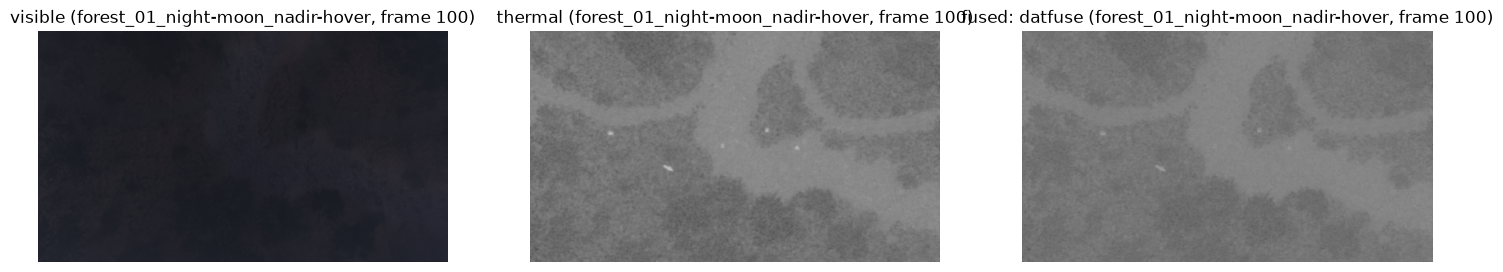

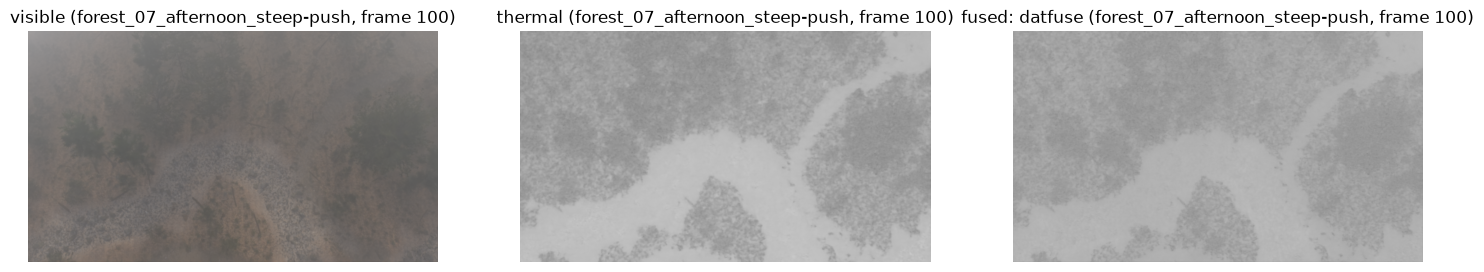

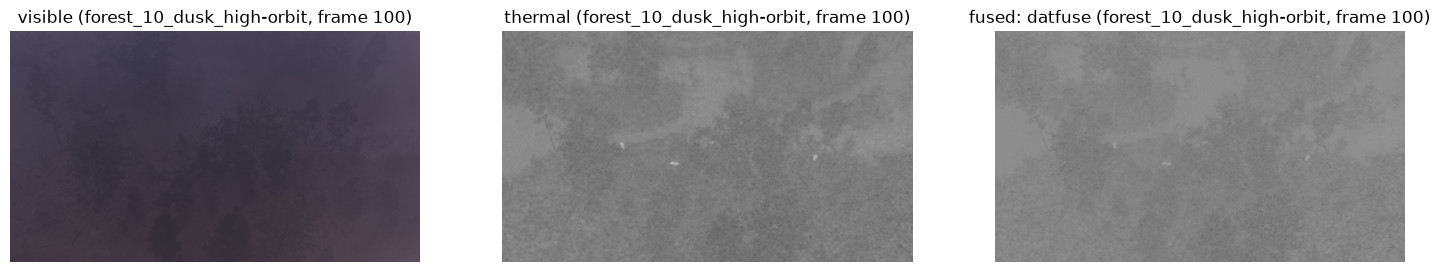

Next: run fusion/FUSION_EVALUATION.ipynb (once per SOURCE) to score datfuse


In [8]:
for SOURCE, (rgb, ir, g, i) in previews.items():
    fig, axes = plt.subplots(1, 3, figsize=(18, 4))
    for ax, img, title in zip(axes, [cv2.cvtColor(rgb, cv2.COLOR_BGR2RGB), ir, g], ['visible', 'thermal', 'fused: ' + METHOD]):
        ax.imshow(img, cmap=None if img.ndim == 3 else 'gray', vmin=0, vmax=255); ax.set_title('%s (%s, frame %d)' % (title, SOURCE, i)); ax.axis('off')
    plt.show()
print('Next: run fusion/FUSION_EVALUATION.ipynb (once per SOURCE) to score', METHOD)